Loaded FITS: /content/hlsp_ceers_jwst_nirspec_nirspec12-080026_prism_dr0.9_x1d-optext-masked_x1d (1).fits
Using columns: {'Wavelength': 'WAVELENGTH', 'Flux': 'FLUX', 'Flux_err': 'FLUX_ERROR'}
N = 401
Wavelength range (um): 0.6045364771319747 to 5.30107167164315
Shifted wavelengths to rest-frame using z=9.95. New CENTER=0.163470 um

==== RESULTS (FITS) ====

                                               method                                                                     window  n                                                    key  SNR_or_sigma                                       notes
                      Window SNR (uses Flux_err) [M1]                                  [0.16118721461187216,0.16529680365296806]  3                    median(flux/err)=1.84, snr_sum=3.57      1.837136                          per-point flux/err
        Dip significance (local cont, scatter σ) [M2] fit ±0.022831050228310504 excl ±0.0009132420091324202 @ 0.1634703196347032 25   w=0.163017, cont

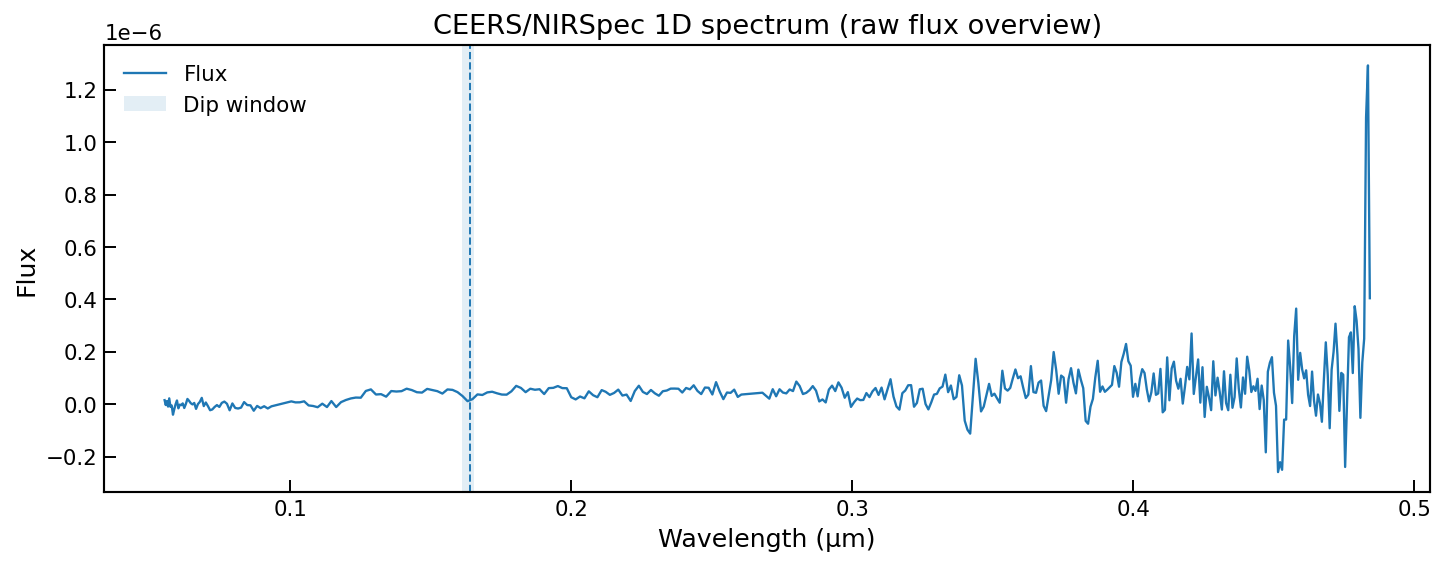

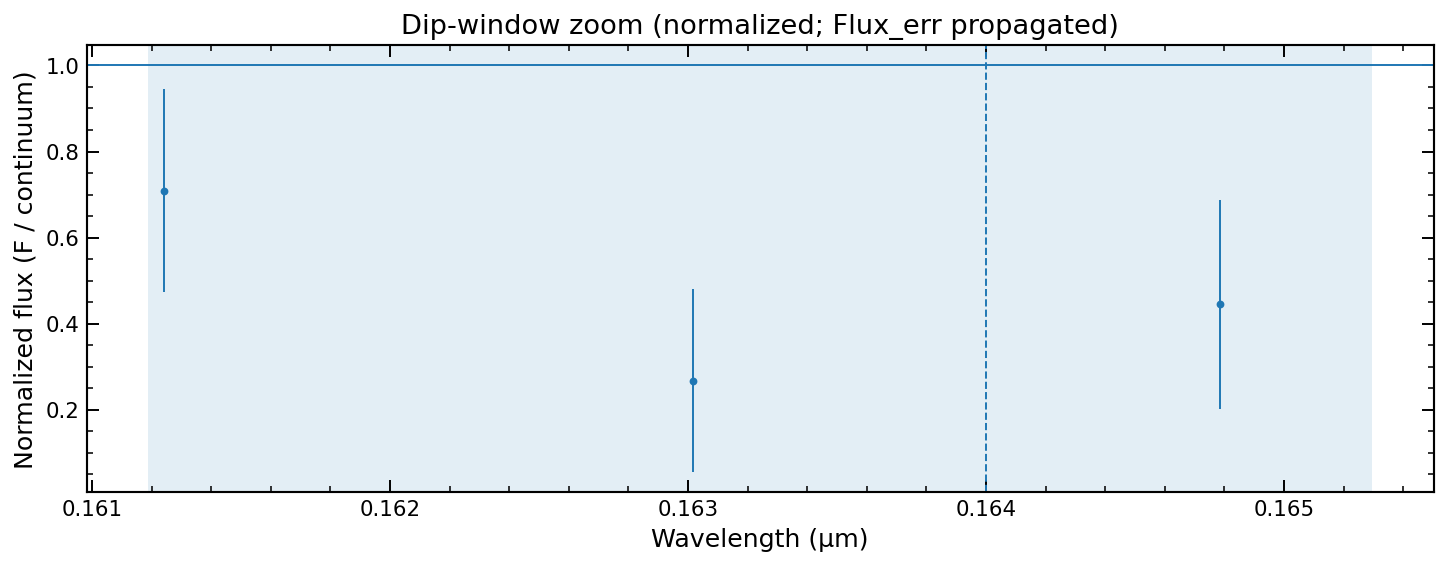

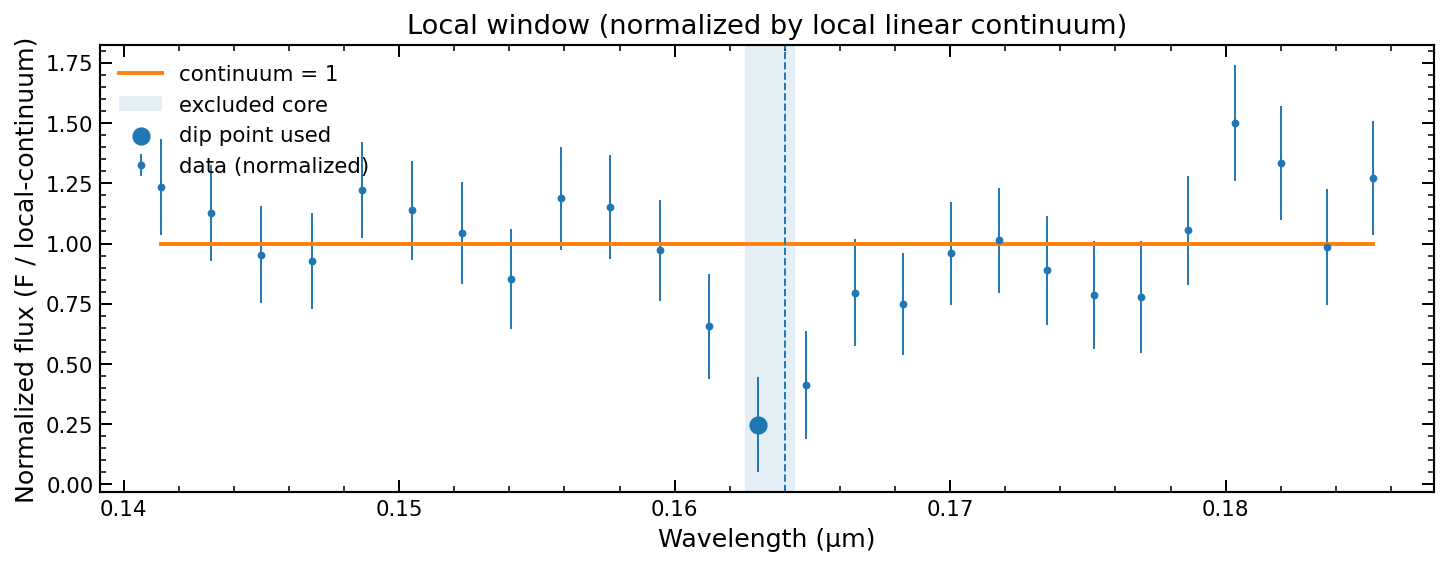

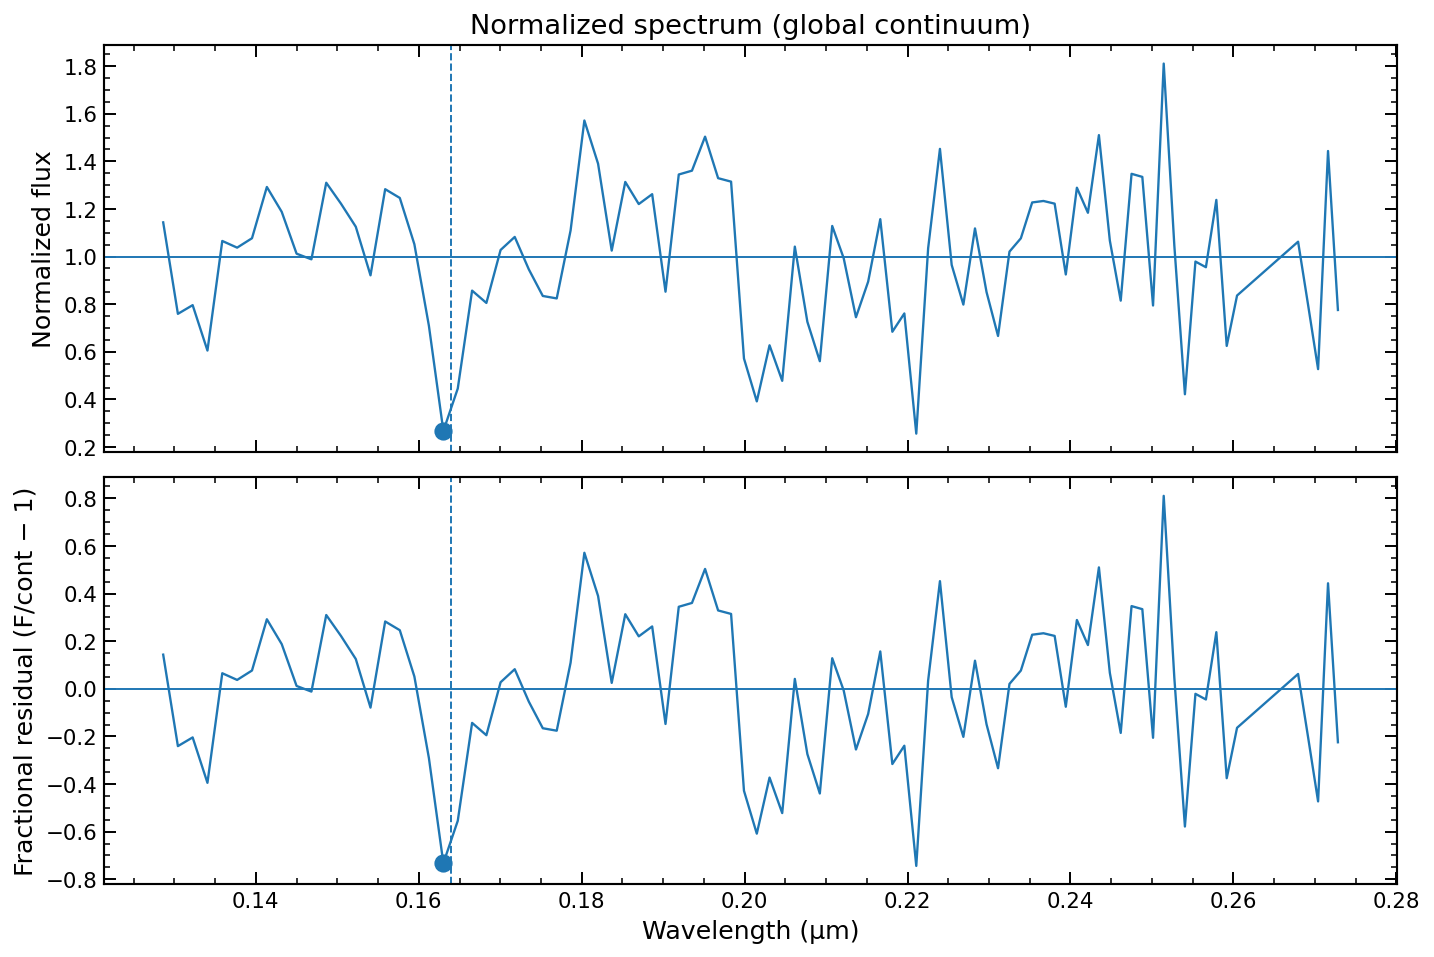

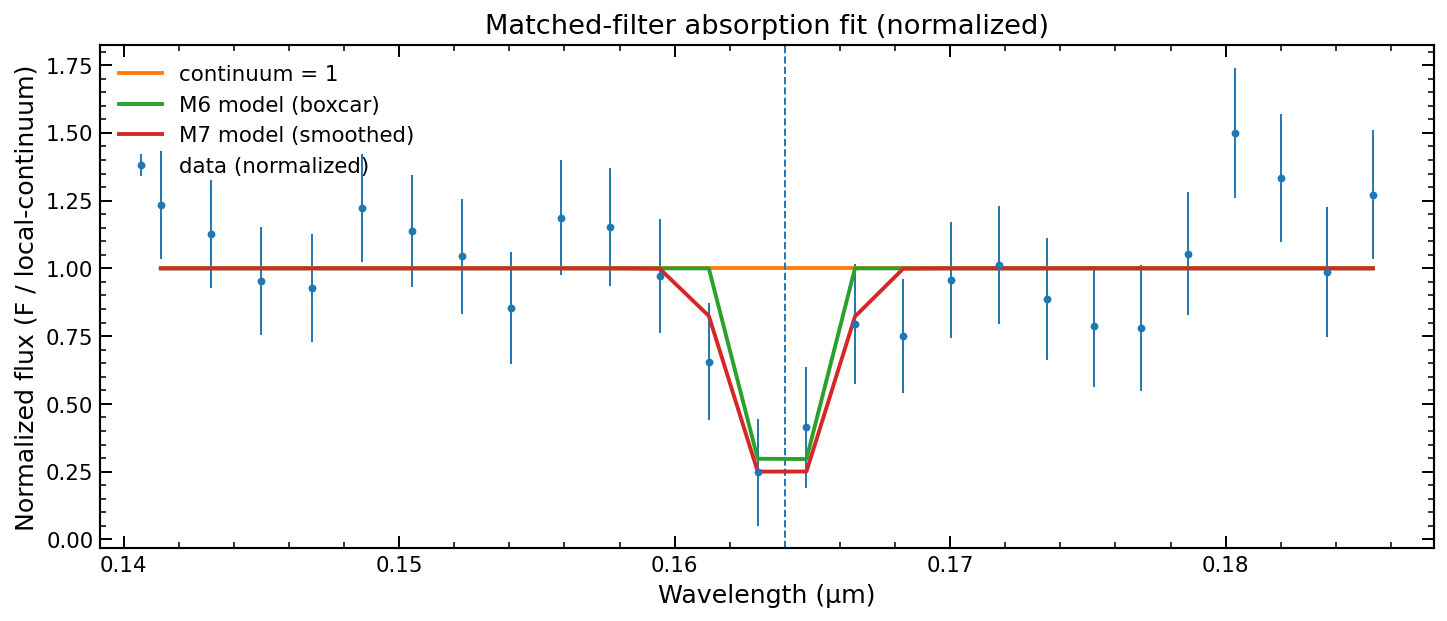

100%|██████████| 3000/3000 [00:18<00:00, 164.56it/s]



==== MCMC RESULT (FITS) ====
 {'ok': True, 'n_window': 26, 'A_16_50_84': (2.5060875811886915e-08, 3.515482849782396e-08, 5.518034832900304e-08), 'lc_16_50_84': (0.1630274150858632, 0.16408772829188578, 0.16626791361890494), 'lsig_16_50_84': (0.002134990199845818, 0.0043579557042843844, 0.021529846468640545), 'delta_chi2': 22.748851482274613, 'snr_dchi2': 4.769575608193523, 'chi2_no_line': 40.75320362064649, 'chi2_with_line': 18.004352138371875}


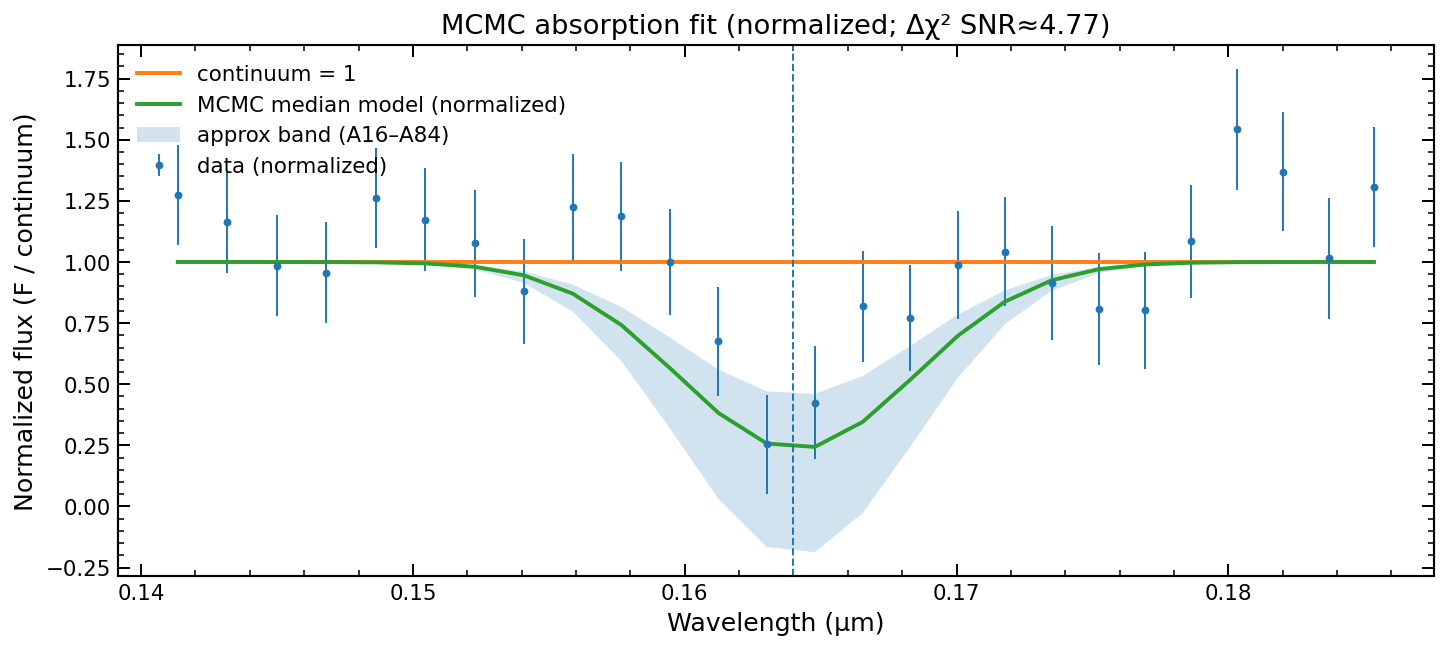

In [ ]:
# ============================================================
# FULL NOTEBOOK (FITS VERSION, WITH ERRORS) — PUBLICATION PLOTS
#   - Load CEERS/NIRSpec 1D x1d FITS
#   - Methods: M1, M2, M3, M4, M6, M7
#   - MCMC cont+Gaussian absorption (emcee; optional jitter)
#   - Summary table
#   - ALL PLOTS IN NORMALIZED FLUX (F/continuum)
#
# You may need:
#   pip install astropy emcee
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table

# ============================================================
# USER SETTINGS
# ============================================================
FITS_PATH = "/content/hlsp_ceers_jwst_nirspec_nirspec12-080026_prism_dr0.9_x1d-optext-masked_x1d (1).fits"

CENTER = 1.79
DIP_W0, DIP_W1 = 1.765, 1.81
HEALTH_W0, HEALTH_W1 = 1.4, 3.0

LOCAL_FIT_HALFWIDTH = 0.25
EXCLUDE_HALFWIDTH   = 0.01

POLY_DEG = 3

# -------- Matched filter settings (methods 6 & 7) --------
MF_WIDTH = 0.030          # boxcar full width (microns)
MF_SMOOTH_SIGMA = 0.006   # Gaussian smoothing sigma (microns)

# MCMC settings
DO_MCMC    = True
N_WALKERS  = 48
N_STEPS    = 3000
N_BURN     = 1000
USE_JITTER = True

# ============================================================
# 1) LOAD FITS -> df
# ============================================================

def _first_present(colnames, candidates):
    cols_lower = {c.lower(): c for c in colnames}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    return None

def _to_numpy_clean(x):
    arr = np.array(x)
    if hasattr(arr, "filled"):  # masked array
        arr = arr.filled(np.nan)
    return np.asarray(arr, dtype=float)

def _maybe_convert_wave_to_um(w):
    """
    Heuristic:
      - median ~1e-7..1e-4 => meters -> microns
      - median ~1e2..1e5   => nm     -> microns
      - else: assume microns
    """
    w = np.asarray(w, float)
    wf = w[np.isfinite(w)]
    if len(wf) < 3:
        return w
    med = float(np.nanmedian(wf))
    if 1e-7 <= med <= 1e-4:
        return w * 1e6
    if 1e2 <= med <= 1e5:
        return w * 1e-3
    return w

t = Table.read(FITS_PATH, hdu=1)
cols = t.colnames

wave_col = _first_present(cols, ["WAVELENGTH", "wave", "wavelength", "lambda", "lam"])
flux_col = _first_present(cols, ["FLUX", "flux", "fnu", "f"])
err_col  = _first_present(cols, ["FLUX_ERROR", "FLUX_ERR", "ERROR", "ERR", "err", "sigma", "uncertainty"])

if wave_col is None or flux_col is None:
    raise ValueError(f"Could not find wavelength/flux columns. Found cols: {cols}")

if err_col is None:
    raise ValueError(
        f"Could not find an error column (FLUX_ERROR/FLUX_ERR/etc). "
        f"Found cols: {cols}\n"
        f"If your file truly has errors, tell me the exact column name shown in `t.colnames`."
    )

w_raw = _to_numpy_clean(t[wave_col])
f_raw = _to_numpy_clean(t[flux_col])
e_raw = _to_numpy_clean(t[err_col])

w_um = _maybe_convert_wave_to_um(w_raw)

df = pd.DataFrame({
    "Wavelength": pd.to_numeric(w_um, errors="coerce"),
    "Flux": pd.to_numeric(f_raw, errors="coerce"),
    "Flux_err": pd.to_numeric(e_raw, errors="coerce"),
})

df = df.replace([np.inf, -np.inf], np.nan).dropna()
df = df[np.isfinite(df["Wavelength"]) & np.isfinite(df["Flux"]) & np.isfinite(df["Flux_err"])]
df = df[df["Flux_err"] > 0]
df = df.sort_values("Wavelength").reset_index(drop=True)

print("Loaded FITS:", FITS_PATH)
print("Using columns:", {"Wavelength": wave_col, "Flux": flux_col, "Flux_err": err_col})
print("N =", len(df))
print("Wavelength range (um):", float(df["Wavelength"].min()), "to", float(df["Wavelength"].max()))

# ============================================================
# 1.5) OPTIONAL: SHIFT WAVELENGTHS BY REDSHIFT
#   - observed -> rest: lam_rest = lam_obs / (1+z)
#   - rest -> observed: lam_obs  = lam_rest * (1+z)
# ============================================================

Z = 9.950
SHIFT_TO = "rest"  # "rest" or "observed"

if SHIFT_TO.lower() == "rest":
    df["Wavelength"] = df["Wavelength"] / (1.0 + Z)
    # IMPORTANT: also shift any wavelength settings to rest-frame (keeps calculations consistent)
    CENTER   = CENTER   / (1.0 + Z)
    DIP_W0   = DIP_W0   / (1.0 + Z)
    DIP_W1   = DIP_W1   / (1.0 + Z)
    HEALTH_W0= HEALTH_W0/ (1.0 + Z)
    HEALTH_W1= HEALTH_W1/ (1.0 + Z)
    LOCAL_FIT_HALFWIDTH = LOCAL_FIT_HALFWIDTH / (1.0 + Z)
    EXCLUDE_HALFWIDTH   = EXCLUDE_HALFWIDTH   / (1.0 + Z)
    MF_WIDTH            = MF_WIDTH            / (1.0 + Z)
    MF_SMOOTH_SIGMA     = MF_SMOOTH_SIGMA     / (1.0 + Z)

elif SHIFT_TO.lower() == "observed":
    df["Wavelength"] = df["Wavelength"] * (1.0 + Z)
    CENTER   = CENTER   * (1.0 + Z)
    DIP_W0   = DIP_W0   * (1.0 + Z)
    DIP_W1   = DIP_W1   * (1.0 + Z)
    HEALTH_W0= HEALTH_W0* (1.0 + Z)
    HEALTH_W1= HEALTH_W1* (1.0 + Z)
    LOCAL_FIT_HALFWIDTH = LOCAL_FIT_HALFWIDTH * (1.0 + Z)
    EXCLUDE_HALFWIDTH   = EXCLUDE_HALFWIDTH   * (1.0 + Z)
    MF_WIDTH            = MF_WIDTH            * (1.0 + Z)
    MF_SMOOTH_SIGMA     = MF_SMOOTH_SIGMA     * (1.0 + Z)

else:
    raise ValueError("SHIFT_TO must be 'rest' or 'observed'")

df = df.sort_values("Wavelength").reset_index(drop=True)
print(f"Shifted wavelengths to {SHIFT_TO}-frame using z={Z}. New CENTER={CENTER:.6f} um")

# ============================================================
# PLOT-ONLY He1640 reference line (DOES NOT AFFECT CALCULATIONS)
# ============================================================

HE1640_REST_UM = 0.1640  # 1640 Å in microns
HE1640_PLOT = HE1640_REST_UM if SHIFT_TO.lower() == "rest" else HE1640_REST_UM * (1.0 + Z)

def add_he1640_line(ax_or_plt, lw=1.0):
    """
    Draw He II 1640 as a dashed vertical line for plotting only.
    Works for both `plt` and an `ax`.
    """
    if hasattr(ax_or_plt, "axvline"):
        ax_or_plt.axvline(HE1640_PLOT, ls="--", lw=lw)
    else:
        raise ValueError("Pass either matplotlib.pyplot (plt) or an Axes object.")

# ============================================================
# 2) HELPERS
# ============================================================

def robust_sigma(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) < 3:
        return np.nan
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return 1.4826 * mad

def safe_div(a, b, eps=1e-30):
    b = np.asarray(b, float)
    return np.asarray(a, float) / np.where(np.abs(b) > eps, b, np.nan)

def _get_window_df(df, center, halfwidth, wave_col="Wavelength"):
    return df[(df[wave_col] >= center - halfwidth) & (df[wave_col] <= center + halfwidth)].copy()

# ============================================================
# 2.5) CONTINUUMS FOR NORMALIZATION
# ============================================================

def poly_continuum_sigma_clip(w, f, deg=3, n_iter=7, clip=3.5):
    w = np.asarray(w, float)
    f = np.asarray(f, float)
    good = np.isfinite(w) & np.isfinite(f)
    w = w[good]; f = f[good]
    if len(w) < deg + 8:
        return None

    m = np.ones_like(f, dtype=bool)
    for _ in range(n_iter):
        if m.sum() < deg + 8:
            break
        p = np.polyfit(w[m], f[m], deg=deg)
        cont = np.polyval(p, w)
        resid = f - cont
        sig = robust_sigma(resid[m])
        if not np.isfinite(sig) or sig <= 0:
            break
        m_new = np.abs(resid) <= clip * sig
        if m_new.sum() == m.sum():
            m = m_new
            break
        m = m_new
    p = np.polyfit(w[m], f[m], deg=deg)
    return p

def local_linear_continuum(df, center=1.79, fit_halfwidth=0.25, exclude_halfwidth=0.01,
                          wave_col="Wavelength", flux_col="Flux"):
    d = df[[wave_col, flux_col]].replace([np.inf, -np.inf], np.nan).dropna().sort_values(wave_col)
    w = d[wave_col].to_numpy(float)
    f = d[flux_col].to_numpy(float)

    m_win = (w >= center - fit_halfwidth) & (w <= center + fit_halfwidth)
    if m_win.sum() < 10:
        return {"ok": False, "message": f"Too few points in window (n={int(m_win.sum())})"}

    wW, fW = w[m_win], f[m_win]
    m_fit = np.abs(wW - center) > exclude_halfwidth
    if m_fit.sum() < 6:
        return {"ok": False, "message": f"Too few points for continuum fit (n={int(m_fit.sum())})"}

    A = np.vstack([wW[m_fit], np.ones_like(wW[m_fit])]).T
    slope, intercept = np.linalg.lstsq(A, fW[m_fit], rcond=None)[0]
    cont = slope * wW + intercept

    return {"ok": True, "w": wW, "f": fW, "cont": cont, "slope": float(slope), "intercept": float(intercept)}

# Build global polynomial continuum in HEALTH range
dH = df[(df["Wavelength"] >= HEALTH_W0) & (df["Wavelength"] <= HEALTH_W1)].copy()
dH = dH.replace([np.inf, -np.inf], np.nan).dropna().sort_values("Wavelength")
p_global = poly_continuum_sigma_clip(
    dH["Wavelength"].to_numpy(float),
    dH["Flux"].to_numpy(float),
    deg=POLY_DEG, n_iter=7, clip=3.5
)
if p_global is None:
    raise RuntimeError("Global continuum fit failed (too few points in health range).")

def eval_global_cont(w):
    return np.polyval(p_global, np.asarray(w, float))

# ============================================================
# 3) METHODS (M1..M4)
# ============================================================

def snr_in_window(df, w0, w1, wave_col="Wavelength", flux_col="Flux", err_col="Flux_err", robust=True):
    d = df[(df[wave_col] >= w0) & (df[wave_col] <= w1)].copy()
    d = d[[wave_col, flux_col, err_col]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(d) < 3:
        return {"ok": False, "message": "Too few points", "n": len(d)}

    f = d[flux_col].to_numpy(float)
    e = d[err_col].to_numpy(float)
    good = np.isfinite(f) & np.isfinite(e) & (e > 0)
    if good.sum() < 3:
        return {"ok": False, "message": "Too few valid error points", "n": int(good.sum())}

    snr_i = f[good] / e[good]
    return {
        "ok": True,
        "snr": float(np.nanmedian(snr_i) if robust else np.nanmean(snr_i)),
        "snr_sum": float(np.nansum(f[good]) / np.sqrt(np.nansum(e[good] ** 2))),
        "n": int(good.sum()),
        "method": "per-point flux/err",
    }

def point_dip_significance_scatter(df, center=1.79, exclude_halfwidth=0.01, fit_halfwidth=0.25,
                                  wave_col="Wavelength", flux_col="Flux", robust=True):
    d = df[[wave_col, flux_col]].replace([np.inf, -np.inf], np.nan).dropna().sort_values(wave_col)
    w = d[wave_col].to_numpy(float)
    f = d[flux_col].to_numpy(float)

    i0 = int(np.argmin(np.abs(w - center)))
    w0, f0 = float(w[i0]), float(f[i0])

    m_fit = (w >= center - fit_halfwidth) & (w <= center + fit_halfwidth) & (np.abs(w - center) > exclude_halfwidth)
    if m_fit.sum() < 6:
        return {"ok": False, "message": f"Too few points for fit ({int(m_fit.sum())})"}

    wf, ff = w[m_fit], f[m_fit]
    A = np.vstack([wf, np.ones_like(wf)]).T
    slope, intercept = np.linalg.lstsq(A, ff, rcond=None)[0]
    cont0 = float(slope * w0 + intercept)

    resid = ff - (slope * wf + intercept)
    sigma = float(robust_sigma(resid) if robust else np.std(resid, ddof=1))
    drop = cont0 - f0
    snr = drop / sigma if (np.isfinite(sigma) and sigma > 0) else np.nan

    return {"ok": True, "nearest_w": w0, "flux": f0, "cont_pred": cont0, "drop": float(drop),
            "sigma_used": sigma, "snr": float(snr), "n_fit": int(m_fit.sum())}

def point_dip_significance_err(df, center=1.79, exclude_halfwidth=0.01, fit_halfwidth=0.25,
                              wave_col="Wavelength", flux_col="Flux", err_col="Flux_err"):
    d = df[[wave_col, flux_col, err_col]].replace([np.inf, -np.inf], np.nan).dropna().sort_values(wave_col)
    w = d[wave_col].to_numpy(float)
    f = d[flux_col].to_numpy(float)
    e = d[err_col].to_numpy(float)

    i0 = int(np.argmin(np.abs(w - center)))
    w0, f0, e0 = float(w[i0]), float(f[i0]), float(e[i0])

    m_fit = (w >= center - fit_halfwidth) & (w <= center + fit_halfwidth) & (np.abs(w - center) > exclude_halfwidth)
    if m_fit.sum() < 6:
        return {"ok": False, "message": f"Too few points for fit ({int(m_fit.sum())})"}

    wf, ff = w[m_fit], f[m_fit]
    A = np.vstack([wf, np.ones_like(wf)]).T
    slope, intercept = np.linalg.lstsq(A, ff, rcond=None)[0]
    cont0 = float(slope * w0 + intercept)

    drop = cont0 - f0
    snr = drop / e0 if (np.isfinite(e0) and e0 > 0) else np.nan

    return {"ok": True, "nearest_w": w0, "flux": f0, "flux_err": e0, "cont_pred": cont0,
            "drop": float(drop), "snr": float(snr), "n_fit": int(m_fit.sum())}

def global_poly_residual_z(df, w0=1.4, w1=3.0, poly_deg=3, wave_col="Wavelength", flux_col="Flux", target=1.79):
    d = df[[wave_col, flux_col]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[wave_col] >= w0) & (d[wave_col] <= w1)].sort_values(wave_col)
    w = d[wave_col].to_numpy(float)
    f = d[flux_col].to_numpy(float)
    if len(w) < poly_deg + 8:
        return {"ok": False, "message": "Too few points for poly fit"}

    p = np.polyfit(w, f, deg=poly_deg)
    cont = np.polyval(p, w)
    resid = f - cont
    sig = robust_sigma(resid)
    z = resid / sig if (np.isfinite(sig) and sig > 0) else np.full_like(resid, np.nan)

    i0 = int(np.argmin(np.abs(w - target)))
    return {"ok": True, "target_w": float(w[i0]), "flux": float(f[i0]), "resid": float(resid[i0]),
            "sigma_resid": float(sig), "z": float(z[i0]), "n": int(len(w))}

# ============================================================
# 4) MATCHED FILTER METHODS (M6/M7)
# ============================================================

def _uniform_grid_from_irregular(w, pad_frac=0.02):
    w = np.asarray(w, float)
    w = w[np.isfinite(w)]
    w = np.sort(w)
    if len(w) < 5:
        return None
    dw = np.diff(w)
    dw = dw[np.isfinite(dw) & (dw > 0)]
    if len(dw) < 2:
        return None
    step = float(np.median(dw))
    wmin, wmax = float(w[0]), float(w[-1])
    pad = pad_frac * (wmax - wmin)
    grid = np.arange(wmin - pad, wmax + pad + step, step)
    return grid, step

def boxcar_template(w, center, width):
    w = np.asarray(w, float)
    half = 0.5 * width
    return ((w >= center - half) & (w <= center + half)).astype(float)

def gaussian_smooth_template_on_irregular(w, t, sigma):
    w = np.asarray(w, float)
    t = np.asarray(t, float)
    ug = _uniform_grid_from_irregular(w)
    if ug is None:
        return t.copy()
    wU, step = ug
    tU = np.interp(wU, w, t, left=0.0, right=0.0)
    sig_pix = sigma / step
    if not np.isfinite(sig_pix) or sig_pix <= 0:
        return t.copy()
    half = int(np.ceil(5.0 * sig_pix))
    x = np.arange(-half, half + 1, dtype=float)
    k = np.exp(-0.5 * (x / sig_pix) ** 2)
    k /= np.sum(k)
    tUs = np.convolve(tU, k, mode="same")
    return np.interp(w, wU, tUs, left=0.0, right=0.0)

def matched_filter_snr_from_residuals(w, r, e, t):
    w = np.asarray(w, float)
    r = np.asarray(r, float)
    t = np.asarray(t, float)
    e = np.asarray(e, float)

    good = np.isfinite(w) & np.isfinite(r) & np.isfinite(t) & np.isfinite(e) & (e > 0)
    if good.sum() < 10:
        return {"ok": False, "message": "Too few valid points", "n": int(good.sum())}

    r = r[good]; t = t[good]; e = e[good]
    W = 1.0 / (e * e)

    tWt = float(np.sum(W * t * t))
    if not np.isfinite(tWt) or tWt <= 0:
        return {"ok": False, "message": "Degenerate template weighting", "n": int(good.sum())}

    tWr = float(np.sum(W * t * r))
    Ahat = tWr / tWt
    sigA = float(np.sqrt(1.0 / tWt))
    snr = Ahat / sigA if (np.isfinite(sigA) and sigA > 0) else np.nan

    return {"ok": True, "n": int(good.sum()), "Ahat": float(Ahat), "sigma_A": float(sigA), "snr": float(snr)}

def run_matched_filter_methods(df, center=1.79, fit_halfwidth=0.25, exclude_halfwidth=0.01,
                               box_width=0.03, smooth_sigma=0.006,
                               wave_col="Wavelength", flux_col="Flux", err_col="Flux_err"):
    d = df[[wave_col, flux_col, err_col]].replace([np.inf, -np.inf], np.nan).dropna().sort_values(wave_col)

    cont_out = local_linear_continuum(d, center=center, fit_halfwidth=fit_halfwidth,
                                      exclude_halfwidth=exclude_halfwidth,
                                      wave_col=wave_col, flux_col=flux_col)
    if not cont_out.get("ok"):
        return {"ok": False, "message": cont_out.get("message")}

    w = cont_out["w"]
    f = cont_out["f"]
    cont = cont_out["cont"]

    # dip-positive residual
    r = cont - f

    # errors aligned to same window
    m_win = (d[wave_col].values >= center - fit_halfwidth) & (d[wave_col].values <= center + fit_halfwidth)
    e = d.loc[m_win, err_col].to_numpy(float)
    if len(e) != len(w):
        e = np.interp(w, d.loc[m_win, wave_col].to_numpy(float), e, left=np.nan, right=np.nan)
    if np.any(~np.isfinite(e)) or np.any(e <= 0):
        e_med = float(np.nanmedian(df[err_col].to_numpy(float)))
        e = np.full_like(w, e_med, dtype=float)

    t6 = boxcar_template(w, center=center, width=box_width)
    t7 = gaussian_smooth_template_on_irregular(w, t6, sigma=smooth_sigma)

    # remove weighted mean
    good = np.isfinite(e) & (e > 0)
    if good.sum() >= 3:
        W = 1.0 / (e[good]**2)
        t6m = np.sum(W * t6[good]) / np.sum(W)
        t7m = np.sum(W * t7[good]) / np.sum(W)
        t6 = t6.copy(); t7 = t7.copy()
        t6[good] -= t6m
        t7[good] -= t7m

    out6 = matched_filter_snr_from_residuals(w, r, e, t6)
    out7 = matched_filter_snr_from_residuals(w, r, e, t7)

    return {"ok": True, "method6": out6, "method7": out7, "n_window": int(len(w)),
            "w": w, "f": f, "cont": cont, "e": e}

# ============================================================
# 5) RUN METHODS + SUMMARY TABLE
# ============================================================

rows = []

r = snr_in_window(df, DIP_W0, DIP_W1, err_col="Flux_err", robust=True)
rows.append({
    "method": "Window SNR (uses Flux_err) [M1]",
    "window": f"[{DIP_W0},{DIP_W1}]",
    "n": r.get("n"),
    "key": (f"median(flux/err)={r.get('snr'):.3g}, snr_sum={r.get('snr_sum'):.3g}" if r.get("ok") else r.get("message")),
    "SNR_or_sigma": r.get("snr") if r.get("ok") else np.nan,
    "notes": r.get("method", ""),
})

r = point_dip_significance_scatter(df, center=CENTER, fit_halfwidth=LOCAL_FIT_HALFWIDTH, exclude_halfwidth=EXCLUDE_HALFWIDTH)
rows.append({
    "method": "Dip significance (local cont, scatter σ) [M2]",
    "window": f"fit ±{LOCAL_FIT_HALFWIDTH} excl ±{EXCLUDE_HALFWIDTH} @ {CENTER}",
    "n": r.get("n_fit"),
    "key": (f"w={r.get('nearest_w'):.6f}, cont={r.get('cont_pred'):.3g}, flux={r.get('flux'):.3g}, σ={r.get('sigma_used'):.3g}"
            if r.get("ok") else r.get("message")),
    "SNR_or_sigma": r.get("snr") if r.get("ok") else np.nan,
    "notes": "σ from MAD(residuals)",
})

r = point_dip_significance_err(df, center=CENTER, fit_halfwidth=LOCAL_FIT_HALFWIDTH, exclude_halfwidth=EXCLUDE_HALFWIDTH, err_col="Flux_err")
rows.append({
    "method": "Dip significance (local cont, Flux_err at point) [M3]",
    "window": f"fit ±{LOCAL_FIT_HALFWIDTH} excl ±{EXCLUDE_HALFWIDTH} @ {CENTER}",
    "n": r.get("n_fit"),
    "key": (f"w={r.get('nearest_w'):.6f}, cont={r.get('cont_pred'):.3g}, flux={r.get('flux'):.3g}, err={r.get('flux_err'):.3g}"
            if r.get("ok") else r.get("message")),
    "SNR_or_sigma": r.get("snr") if r.get("ok") else np.nan,
    "notes": "SNR=(cont-flux)/Flux_err",
})

r = global_poly_residual_z(df, w0=HEALTH_W0, w1=HEALTH_W1, poly_deg=POLY_DEG, target=CENTER)
rows.append({
    "method": "Outlier z (poly residuals, MAD σ) [M4]",
    "window": f"[{HEALTH_W0},{HEALTH_W1}]",
    "n": r.get("n"),
    "key": (f"w={r.get('target_w'):.6f}, resid={r.get('resid'):.3g}, σ_resid={r.get('sigma_resid'):.3g}"
            if r.get("ok") else r.get("message")),
    "SNR_or_sigma": (abs(r.get("z")) if r.get("ok") else np.nan),
    "notes": "|z| where z=resid/σ_resid",
})

mf = run_matched_filter_methods(
    df, center=CENTER, fit_halfwidth=LOCAL_FIT_HALFWIDTH, exclude_halfwidth=EXCLUDE_HALFWIDTH,
    box_width=MF_WIDTH, smooth_sigma=MF_SMOOTH_SIGMA
)

if mf.get("ok"):
    r6 = mf["method6"]; r7 = mf["method7"]
    rows.append({
        "method": "Matched filter (boxcar template) [M6]",
        "window": f"fit ±{LOCAL_FIT_HALFWIDTH} excl ±{EXCLUDE_HALFWIDTH} @ {CENTER}",
        "n": r6.get("n"),
        "key": (f"Ahat={r6.get('Ahat'):.3g}, σA={r6.get('sigma_A'):.3g}" if r6.get("ok") else r6.get("message")),
        "SNR_or_sigma": r6.get("snr") if r6.get("ok") else np.nan,
        "notes": f"boxcar width={MF_WIDTH:.4f} µm; uses Flux_err",
    })
    rows.append({
        "method": "Matched filter (Gaussian-smoothed template) [M7]",
        "window": f"fit ±{LOCAL_FIT_HALFWIDTH} excl ±{EXCLUDE_HALFWIDTH} @ {CENTER}",
        "n": r7.get("n"),
        "key": (f"Ahat={r7.get('Ahat'):.3g}, σA={r7.get('sigma_A'):.3g}" if r7.get("ok") else r7.get("message")),
        "SNR_or_sigma": r7.get("snr") if r7.get("ok") else np.nan,
        "notes": f"boxcar width={MF_WIDTH:.4f} µm smoothed σ={MF_SMOOTH_SIGMA:.4f} µm",
    })
else:
    rows.append({"method":"Matched filter (boxcar) [M6]","window":"","n":np.nan,"key":mf.get("message","fail"),"SNR_or_sigma":np.nan,"notes":""})
    rows.append({"method":"Matched filter (smoothed) [M7]","window":"","n":np.nan,"key":mf.get("message","fail"),"SNR_or_sigma":np.nan,"notes":""})

results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 220)
print("\n==== RESULTS (FITS) ====\n")
print(results.to_string(index=False))

# ============================================================
# 6) PUBLICATION-QUALITY NORMALIZED PLOTS
# ============================================================

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "axes.linewidth": 1.1,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.minor.size": 3,
    "ytick.minor.size": 3,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.minor.width": 0.8,
    "ytick.minor.width": 0.8,
    "axes.grid": False,
    "legend.fontsize": 11,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
})

def _style_ax(ax):
    ax.tick_params(which="both", top=True, right=True)
    ax.minorticks_on()

# ============================================================
# Plot A (OVERVIEW): RAW FLUX (NOT NORMALIZED)
# ============================================================

w_all = df["Wavelength"].to_numpy(float)
f_all = df["Flux"].to_numpy(float)
e_all = df["Flux_err"].to_numpy(float)

plt.figure(figsize=(10.5, 4.2))
plt.plot(w_all, f_all, lw=1.2, label="Flux")

add_he1640_line(plt, lw=1.0)  # <-- He1640 line (plot-only)
plt.axvspan(DIP_W0, DIP_W1, alpha=0.12, label="Dip window")

plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux")
plt.title("CEERS/NIRSpec 1D spectrum (raw flux overview)")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# ============================================================
# Plot B: dip window zoom normalized by GLOBAL continuum
# ============================================================

m1 = (df["Wavelength"] >= DIP_W0) & (df["Wavelength"] <= DIP_W1)
d1 = df.loc[m1].copy()
w1 = d1["Wavelength"].to_numpy(float)
cont1 = eval_global_cont(w1)
f1n = safe_div(d1["Flux"].to_numpy(float), cont1)
e1n = safe_div(d1["Flux_err"].to_numpy(float), cont1)

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.errorbar(w1, f1n, yerr=e1n, fmt="o", ms=3.0, lw=1.0, capsize=0)
ax.axhline(1.0, lw=1.0)
add_he1640_line(ax, lw=1.0)  # <-- He1640 line (plot-only)
ax.axvspan(DIP_W0, DIP_W1, alpha=0.12)
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Normalized flux (F / continuum)")
ax.set_title("Dip-window zoom (normalized; Flux_err propagated)")
_style_ax(ax)
fig.tight_layout()
plt.show()

# ============================================================
# Plot C: local window normalized by LOCAL continuum
# ============================================================

cont_out = local_linear_continuum(df, center=CENTER, fit_halfwidth=LOCAL_FIT_HALFWIDTH, exclude_halfwidth=EXCLUDE_HALFWIDTH)
if cont_out.get("ok"):
    wW   = np.asarray(cont_out["w"], float)
    fW   = np.asarray(cont_out["f"], float)
    cont = np.asarray(cont_out["cont"], float)

    dwin = _get_window_df(df, CENTER, LOCAL_FIT_HALFWIDTH).copy()
    dwin = dwin.replace([np.inf, -np.inf], np.nan).dropna().sort_values("Wavelength")
    ew = np.interp(wW, dwin["Wavelength"].to_numpy(float), dwin["Flux_err"].to_numpy(float),
                   left=np.nan, right=np.nan)

    fWn = safe_div(fW, cont)
    eWn = safe_div(ew, cont)

    i0 = int(np.argmin(np.abs(wW - CENTER)))
    fig, ax = plt.subplots(figsize=(10.5, 4.2))
    ax.errorbar(wW, fWn, yerr=eWn, fmt="o", ms=3.0, lw=1.0, capsize=0, label="data (normalized)")
    ax.plot(wW, np.ones_like(wW), lw=2.0, label="continuum = 1")
    add_he1640_line(ax, lw=1.0)  # <-- He1640 line (plot-only)
    ax.axvspan(CENTER-EXCLUDE_HALFWIDTH, CENTER+EXCLUDE_HALFWIDTH, alpha=0.12, label="excluded core")
    ax.scatter([wW[i0]], [fWn[i0]], s=70, zorder=6, label="dip point used")
    ax.set_xlabel("Wavelength (µm)")
    ax.set_ylabel("Normalized flux (F / local-continuum)")
    ax.set_title("Local window (normalized by local linear continuum)")
    ax.legend(loc="best")
    _style_ax(ax)
    fig.tight_layout()
    plt.show()
else:
    print("Local continuum plot skipped:", cont_out.get("message"))

# ============================================================
# Plot D: health range normalized + fractional residuals
# ============================================================

d4 = df[(df["Wavelength"] >= HEALTH_W0) & (df["Wavelength"] <= HEALTH_W1)].copy()
d4 = d4.replace([np.inf, -np.inf], np.nan).dropna().sort_values("Wavelength")
w4 = d4["Wavelength"].to_numpy(float)
cont4 = eval_global_cont(w4)
f4n = safe_div(d4["Flux"].to_numpy(float), cont4)
resid_frac = f4n - 1.0
iT = int(np.argmin(np.abs(w4 - CENTER)))

fig, ax = plt.subplots(2, 1, figsize=(10.5, 7.0), sharex=True)
ax[0].plot(w4, f4n, lw=1.2)
ax[0].axhline(1.0, lw=1.0)
add_he1640_line(ax[0], lw=1.0)  # <-- He1640 line (plot-only)
ax[0].scatter([w4[iT]], [f4n[iT]], s=70, zorder=6)
ax[0].set_ylabel("Normalized flux")
ax[0].set_title("Normalized spectrum (global continuum)")
_style_ax(ax[0])

ax[1].plot(w4, resid_frac, lw=1.2)
ax[1].axhline(0.0, lw=1.0)
add_he1640_line(ax[1], lw=1.0)  # <-- He1640 line (plot-only)
ax[1].scatter([w4[iT]], [resid_frac[iT]], s=70, zorder=6)
ax[1].set_xlabel("Wavelength (µm)")
ax[1].set_ylabel("Fractional residual (F/cont − 1)")
_style_ax(ax[1])

fig.tight_layout()
plt.show()

# ============================================================
# Plot E: matched-filter absorption fit in NORMALIZED space (local continuum)
# ============================================================

if mf.get("ok") and mf["method6"].get("ok") and mf["method7"].get("ok"):
    w    = np.asarray(mf["w"], float)
    f    = np.asarray(mf["f"], float)
    cont = np.asarray(mf["cont"], float)
    e    = np.asarray(mf["e"], float)

    t6 = boxcar_template(w, center=CENTER, width=MF_WIDTH)
    t7 = gaussian_smooth_template_on_irregular(w, t6, sigma=MF_SMOOTH_SIGMA)

    A6 = float(mf["method6"].get("Ahat", np.nan))
    A7 = float(mf["method7"].get("Ahat", np.nan))

    fn = safe_div(f, cont)
    en = safe_div(e, cont)

    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.errorbar(w, fn, yerr=en, fmt="o", ms=3.0, lw=1.0, capsize=0, label="data (normalized)")
    ax.plot(w, np.ones_like(w), lw=2.0, label="continuum = 1")
    add_he1640_line(ax, lw=1.0)  # <-- He1640 line (plot-only)

    if np.isfinite(A6):
        ax.plot(w, 1.0 - safe_div(A6 * t6, cont), lw=2.0, label=f"M6 model (boxcar)")
    if np.isfinite(A7):
        ax.plot(w, 1.0 - safe_div(A7 * t7, cont), lw=2.0, label=f"M7 model (smoothed)")

    ax.set_xlabel("Wavelength (µm)")
    ax.set_ylabel("Normalized flux (F / local-continuum)")
    ax.set_title("Matched-filter absorption fit (normalized)")
    ax.legend(loc="best")
    _style_ax(ax)
    fig.tight_layout()
    plt.show()
else:
    print("Matched filter plot skipped:", mf.get("message"))

# ============================================================
# 7) MCMC (emcee): continuum + Gaussian absorption, normalized plot
# ============================================================

mcmc = None
if DO_MCMC:
    try:
        import emcee
    except Exception:
        !pip -q install emcee
        import emcee

    def fit_absorption_mcmc(
        df,
        center=1.79,
        fit_halfwidth=0.25,
        wave_col="Wavelength",
        flux_col="Flux",
        err_col="Flux_err",
        lc_prior_width=0.02,
        lsig_min=3e-4,
        lsig_max=0.03,
        A_max_factor=5.0,
        nwalkers=48,
        nsteps=3000,
        nburn=1000,
        seed=123,
        use_jitter=True,
    ):
        rng = np.random.default_rng(seed)

        d = df[[wave_col, flux_col, err_col]].replace([np.inf, -np.inf], np.nan).dropna()
        d = d[(d[wave_col] >= center - fit_halfwidth) & (d[wave_col] <= center + fit_halfwidth)].copy()
        d = d[np.isfinite(d[err_col]) & (d[err_col] > 0)].sort_values(wave_col)
        if len(d) < 10:
            return {"ok": False, "message": f"Too few points in window (n={len(d)})"}

        w = d[wave_col].to_numpy(float)
        f = d[flux_col].to_numpy(float)
        e = d[err_col].to_numpy(float)

        f05, f95 = np.nanpercentile(f, [5, 95])
        fspan = float(f95 - f05)
        if not np.isfinite(fspan) or fspan <= 0:
            fspan = float(np.nanstd(f)) if np.isfinite(np.nanstd(f)) else 1.0

        A_lin = np.vstack([w, np.ones_like(w)]).T
        m0, b0 = np.linalg.lstsq(A_lin, f, rcond=None)[0]
        A_max = A_max_factor * fspan

        def model(theta):
            if use_jitter:
                m, b, A, lc, lsig, logs = theta
                s = np.exp(logs)
            else:
                m, b, A, lc, lsig = theta
                s = 0.0
            g = np.exp(-0.5*((w - lc)/lsig)**2)
            return (m*w + b) - A*g, s

        def log_prior(theta):
            if use_jitter:
                m, b, A, lc, lsig, logs = theta
            else:
                m, b, A, lc, lsig = theta

            if not (np.isfinite(m) and np.isfinite(b) and np.isfinite(A) and np.isfinite(lc) and np.isfinite(lsig)):
                return -np.inf
            if (A < 0) or (A > A_max):
                return -np.inf
            if (lc < center - lc_prior_width) or (lc > center + lc_prior_width):
                return -np.inf
            if (lsig < lsig_min) or (lsig > lsig_max):
                return -np.inf

            lp = 0.0
            lp += -0.5*((m - m0)/(10*np.abs(m0) + 1e-30))**2
            lp += -0.5*((b - b0)/(10*np.abs(b0) + 1e-30))**2

            if use_jitter:
                med_e = float(np.nanmedian(e))
                s_min = 1e-3*med_e
                s_max = 10.0*med_e
                s = np.exp(logs)
                if (s < s_min) or (s > s_max):
                    return -np.inf
            return lp

        def log_likelihood(theta):
            yhat, s = model(theta)
            sig2 = e**2 + s**2
            if np.any(sig2 <= 0) or np.any(~np.isfinite(sig2)):
                return -np.inf
            r = f - yhat
            return -0.5*np.sum(r*r/sig2 + np.log(2*np.pi*sig2))

        def log_prob(theta):
            lp = log_prior(theta)
            if not np.isfinite(lp):
                return -np.inf
            ll = log_likelihood(theta)
            if not np.isfinite(ll):
                return -np.inf
            return lp + ll

        i0 = int(np.argmin(np.abs(w - center)))
        drop_guess = (m0*w[i0] + b0) - f[i0]
        A_init = float(np.clip(drop_guess, 0.0, A_max*0.5))
        lc_init = float(w[i0])
        lsig_init = float(np.clip(np.median(np.diff(w))*2.0, lsig_min*2, lsig_max/5))

        if use_jitter:
            logs_init = np.log(0.3*np.nanmedian(e))
            ndim = 6
            theta0 = np.array([m0, b0, A_init, lc_init, lsig_init, logs_init], float)
            scale = np.array([abs(m0)+1e-30, abs(b0)+1e-30, fspan, 0.002, 0.002, 0.5], float)
        else:
            ndim = 5
            theta0 = np.array([m0, b0, A_init, lc_init, lsig_init], float)
            scale = np.array([abs(m0)+1e-30, abs(b0)+1e-30, fspan, 0.002, 0.002], float)

        p0 = theta0 + 1e-2*scale*rng.standard_normal(size=(nwalkers, ndim))
        sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)
        sampler.run_mcmc(p0, nsteps, progress=True)

        chain = sampler.get_chain(discard=nburn, flat=True)
        if chain.shape[0] < 200:
            return {"ok": False, "message": "Too few post-burn samples. Increase nsteps or reduce nburn."}

        if use_jitter:
            m_s, b_s, A_s, lc_s, lsig_s, logs_s = chain.T
        else:
            m_s, b_s, A_s, lc_s, lsig_s = chain.T

        def q16_50_84(x):
            return np.percentile(x, [16, 50, 84])

        A16, A50, A84 = q16_50_84(A_s)
        lc16, lc50, lc84 = q16_50_84(lc_s)
        ls16, ls50, ls84 = q16_50_84(lsig_s)

        lc_fix = float(lc50)
        ls_fix = float(ls50)
        g = np.exp(-0.5*((w - lc_fix)/ls_fix)**2)

        if use_jitter:
            s_s = np.exp(logs_s)
            s_med = float(np.median(s_s))
            sig = np.sqrt(e**2 + s_med**2)
        else:
            sig = e.copy()

        W = 1.0/(sig**2)

        X1 = np.vstack([w, np.ones_like(w), -g]).T
        XtW = X1.T * W
        beta1 = np.linalg.lstsq(XtW @ X1, XtW @ f, rcond=None)[0]
        f1 = X1 @ beta1
        chi2_1 = float(np.sum(((f - f1)/sig)**2))

        X0 = np.vstack([w, np.ones_like(w)]).T
        XtW0 = X0.T * W
        beta0 = np.linalg.lstsq(XtW0 @ X0, XtW0 @ f, rcond=None)[0]
        f0m = X0 @ beta0
        chi2_0 = float(np.sum(((f - f0m)/sig)**2))

        dchi2 = max(0.0, chi2_0 - chi2_1)
        snr_dchi2 = float(np.sqrt(dchi2))

        return {
            "ok": True,
            "n_window": int(len(w)),
            "A_16_50_84": (float(A16), float(A50), float(A84)),
            "lc_16_50_84": (float(lc16), float(lc50), float(lc84)),
            "lsig_16_50_84": (float(ls16), float(ls50), float(ls84)),
            "delta_chi2": float(dchi2),
            "snr_dchi2": float(snr_dchi2),
            "chi2_no_line": float(chi2_0),
            "chi2_with_line": float(chi2_1),
        }

    mcmc = fit_absorption_mcmc(
        df, center=CENTER, fit_halfwidth=LOCAL_FIT_HALFWIDTH,
        nwalkers=N_WALKERS, nsteps=N_STEPS, nburn=N_BURN, use_jitter=USE_JITTER
    )

    print("\n==== MCMC RESULT (FITS) ====\n", mcmc)

    if mcmc.get("ok"):
        A16,A50,A84 = mcmc["A_16_50_84"]
        lc16,lc50,lc84 = mcmc["lc_16_50_84"]
        ls16,ls50,ls84 = mcmc["lsig_16_50_84"]

        # Normalized MCMC plot: divide by linear continuum cont=m0*w+b0
        d = _get_window_df(df, CENTER, LOCAL_FIT_HALFWIDTH).copy()
        d = d.replace([np.inf, -np.inf], np.nan).dropna()
        d = d[np.isfinite(d["Flux_err"]) & (d["Flux_err"] > 0)].sort_values("Wavelength")
        w = d["Wavelength"].to_numpy(float)
        f = d["Flux"].to_numpy(float)
        e = d["Flux_err"].to_numpy(float)

        A_lin = np.vstack([w, np.ones_like(w)]).T
        m0, b0 = np.linalg.lstsq(A_lin, f, rcond=None)[0]
        cont = m0*w + b0

        def gauss(x, mu, sig):
            return np.exp(-0.5*((x - mu)/sig)**2)

        g = gauss(w, lc50, ls50)
        model_med = cont - A50 * g
        model_lo  = cont - A84 * g
        model_hi  = cont - A16 * g

        fn = safe_div(f, cont)
        en = safe_div(e, cont)

        fig, ax = plt.subplots(figsize=(10.5, 4.8))
        ax.errorbar(w, fn, yerr=en, fmt="o", ms=3.0, lw=1.0, capsize=0, label="data (normalized)")
        ax.plot(w, np.ones_like(w), lw=2.0, label="continuum = 1")
        ax.plot(w, safe_div(model_med, cont), lw=2.0, label="MCMC median model (normalized)")
        ax.fill_between(w, safe_div(model_lo, cont), safe_div(model_hi, cont), alpha=0.20, label="approx band (A16–A84)")
        add_he1640_line(ax, lw=1.0)  # <-- He1640 line (plot-only)
        ax.set_xlabel("Wavelength (µm)")
        ax.set_ylabel("Normalized flux (F / continuum)")
        ax.set_title(f"MCMC absorption fit (normalized; Δχ² SNR≈{mcmc['snr_dchi2']:.2f})")
        ax.legend(loc="best")
        _style_ax(ax)
        fig.tight_layout()
        plt.show()
    else:
        print("MCMC failed:", mcmc.get("message"))

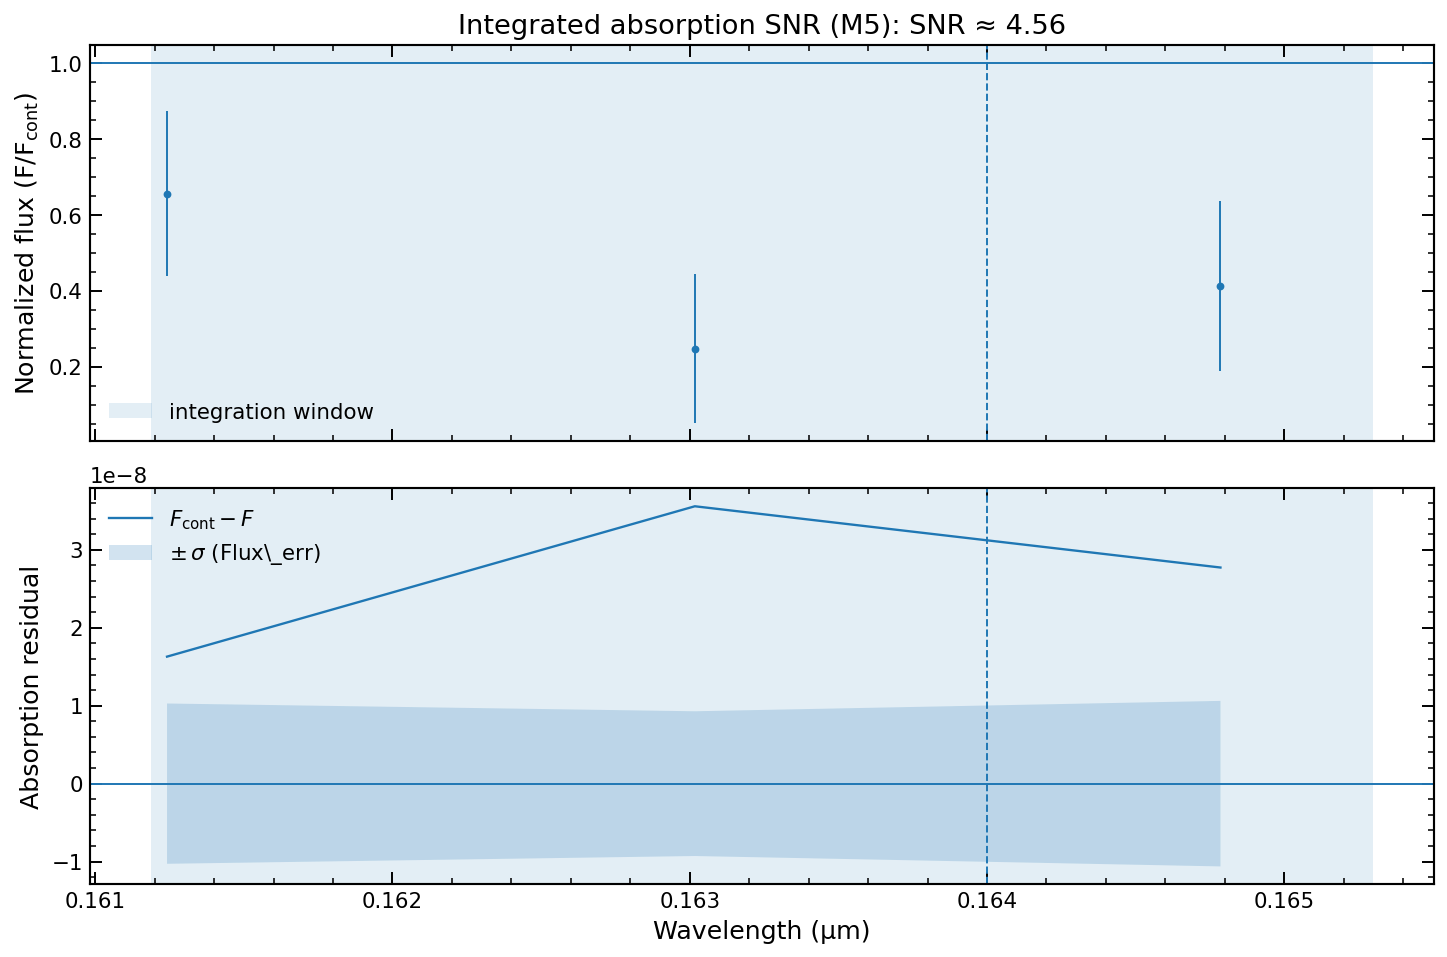

In [ ]:
# ============================================================
# 3.5) NEW METHOD (M5): Integrated absorption SNR (continuum-subtracted)
#   SNR_abs = sum_i (Fcont_i - F_i) / sqrt(sum_i sigma_i^2)
#   - uses a local linear continuum (same fit style as M2/M3)
#   - integrates over a chosen window (default: DIP_W0..DIP_W1)
# ============================================================

def integrated_absorption_snr(
    df,
    center,
    fit_halfwidth,
    exclude_halfwidth,
    integ_w0,
    integ_w1,
    wave_col="Wavelength",
    flux_col="Flux",
    err_col="Flux_err",
):
    # 1) fit local continuum (line excluded)
    cont_out = local_linear_continuum(
        df, center=center, fit_halfwidth=fit_halfwidth, exclude_halfwidth=exclude_halfwidth,
        wave_col=wave_col, flux_col=flux_col
    )
    if not cont_out.get("ok"):
        return {"ok": False, "message": f"Continuum fit failed: {cont_out.get('message','')}"}

    # 2) evaluate continuum on ALL points in the integration window
    d = df[(df[wave_col] >= integ_w0) & (df[wave_col] <= integ_w1)].copy()
    d = d[[wave_col, flux_col, err_col]].replace([np.inf, -np.inf], np.nan).dropna().sort_values(wave_col)
    if len(d) < 3:
        return {"ok": False, "message": f"Too few points in integration window (n={len(d)})"}

    w = d[wave_col].to_numpy(float)
    f = d[flux_col].to_numpy(float)
    e = d[err_col].to_numpy(float)
    good = np.isfinite(w) & np.isfinite(f) & np.isfinite(e) & (e > 0)
    if good.sum() < 3:
        return {"ok": False, "message": "Too few valid error points in integration window"}

    w = w[good]; f = f[good]; e = e[good]

    # local continuum parameters from the fit output
    # (cont_out["cont"] is evaluated on the fit window grid; rebuild m,b using stored slope/intercept)
    m = float(cont_out["slope"])
    b = float(cont_out["intercept"])
    fcont = m*w + b

    # 3) absorption residuals and propagated noise
    r = fcont - f  # absorption => positive residual
    num = float(np.sum(r))
    den = float(np.sqrt(np.sum(e**2)))

    snr = num / den if (np.isfinite(den) and den > 0) else np.nan

    return {
        "ok": True,
        "n": int(len(w)),
        "snr": float(snr),
        "sum_residual": float(num),
        "sigma_sum": float(den),
        "w": w,
        "f": f,
        "e": e,
        "fcont": fcont,
        "resid": r,
        "integ_window": (float(integ_w0), float(integ_w1)),
    }


# -------------------- NEW: M5 integrated absorption SNR --------------------
r = integrated_absorption_snr(
    df,
    center=CENTER,
    fit_halfwidth=LOCAL_FIT_HALFWIDTH,
    exclude_halfwidth=EXCLUDE_HALFWIDTH,
    integ_w0=DIP_W0,
    integ_w1=DIP_W1,
    err_col="Flux_err",
)

rows.append({
    "method": "Integrated absorption SNR (Σ(Fcont−F)/√Σσ²) [M5]",
    "window": f"cont fit ±{LOCAL_FIT_HALFWIDTH} excl ±{EXCLUDE_HALFWIDTH}; integrate [{DIP_W0},{DIP_W1}]",
    "n": r.get("n"),
    "key": (f"Σ(Fcont−F)={r.get('sum_residual'):.3g}, √Σσ²={r.get('sigma_sum'):.3g}" if r.get("ok") else r.get("message")),
    "SNR_or_sigma": r.get("snr") if r.get("ok") else np.nan,
    "notes": "classic integrated-line SNR, adapted for absorption",
})



# ============================================================
# Plot F: Integrated absorption SNR (M5) visualization
#   - Top: normalized flux in the integration window
#   - Bottom: absorption residual (Fcont - F) with ±σ band
# ============================================================

m5 = integrated_absorption_snr(
    df,
    center=CENTER,
    fit_halfwidth=LOCAL_FIT_HALFWIDTH,
    exclude_halfwidth=EXCLUDE_HALFWIDTH,
    integ_w0=DIP_W0,
    integ_w1=DIP_W1,
    err_col="Flux_err",
)

if m5.get("ok"):
    w = m5["w"]
    f = m5["f"]
    e = m5["e"]
    fcont = m5["fcont"]
    r = m5["resid"]

    fn = safe_div(f, fcont)
    en = safe_div(e, fcont)

    fig, ax = plt.subplots(2, 1, figsize=(10.5, 7.0), sharex=True)

    # --- top: normalized spectrum ---
    ax[0].errorbar(w, fn, yerr=en, fmt="o", ms=3.0, lw=1.0, capsize=0)
    ax[0].axhline(1.0, lw=1.0)
    add_he1640_line(ax[0], lw=1.0)
    ax[0].axvspan(DIP_W0, DIP_W1, alpha=0.12, label="integration window")
    ax[0].set_ylabel("Normalized flux (F/F$_{\\rm cont}$)")
    ax[0].set_title(f"Integrated absorption SNR (M5): SNR ≈ {m5['snr']:.2f}")
    ax[0].legend(loc="best")
    _style_ax(ax[0])

    # --- bottom: residuals being summed ---
    ax[1].plot(w, r, lw=1.2, label=r"$F_{\rm cont}-F$")
    ax[1].fill_between(w, -e, +e, alpha=0.20, label=r"$\pm\,\sigma$ (Flux\_err)")
    ax[1].axhline(0.0, lw=1.0)
    add_he1640_line(ax[1], lw=1.0)
    ax[1].axvspan(DIP_W0, DIP_W1, alpha=0.12)
    ax[1].set_xlabel("Wavelength (µm)")
    ax[1].set_ylabel("Absorption residual")
    ax[1].legend(loc="best")
    _style_ax(ax[1])

    fig.tight_layout()
    plt.show()
else:
    print("M5 plot skipped:", m5.get("message"))

In [ ]:
print(rows[6])

{'method': 'Integrated absorption SNR (Σ(Fcont−F)/√Σσ²) [M5]', 'window': 'cont fit ±0.022831050228310504 excl ±0.0009132420091324202; integrate [0.16118721461187216,0.16529680365296806]', 'n': 3, 'key': 'Σ(Fcont−F)=7.96e-08, √Σσ²=1.75e-08', 'SNR_or_sigma': 4.560458241122083, 'notes': 'classic integrated-line SNR, adapted for absorption'}
